# Iris Classifier: Decision Tree (IT Career Switch Exercise)

This notebook builds a decision-tree classifier that sorts out flowers into one of 3 groups/ species (setosa, versicolor, virginica) using four measurements each. 

It follows the following learning workflow:
1. Loads the data
2. Splits it into training and test groups
3. Trains the model 
4. Predictions
5. Evaluation

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 1. Loads the data

The Iris dataset ships with scikit-learn: 150 flowers, 4 measurements each, 50 of each species.

In [2]:
iris = load_iris()
X = iris.data      # features: 150 rows x 4 measurements
y = iris.target    # labels: 0 = setosa, 1 = versicolor, 2 = virginica

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", iris.feature_names)
print("Species:", iris.target_names)

X shape: (150, 4)
y shape: (150,)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species: ['setosa' 'versicolor' 'virginica']


## 2. Splits it into training and test groups

20% of the flowers are held back as a test set the model never sees during training. We can measure how well it performs on new data. `random_state=42` makes the split reproducible.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 120
Test samples: 30


## 3. Trains the model

A decision tree learns a series of yes/no questions about the measurements that separate the species.

In [4]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

## 4. Predictions

The trained model predicts the species of each of the 30 test flowers.

In [5]:
y_pred = model.predict(X_test)

print("Predictions: ", y_pred[:5])
print("True labels: ", y_test[:5])
print("As species:  ", iris.target_names[y_pred[:5]])

Predictions:  [1 0 2 1 1]
True labels:  [1 0 2 1 1]
As species:   ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor']


## 5. Evaluation

Accuracy gives the overall proportion correct.

In [6]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 1.000

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



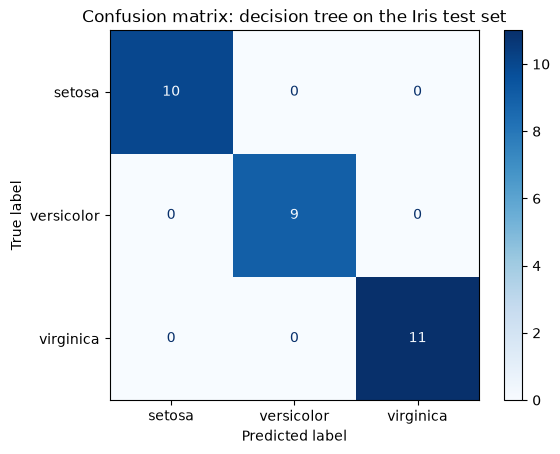

In [7]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=iris.target_names, cmap="Blues"
)
plt.title("Confusion matrix: decision tree on the Iris test set")
plt.show()

## 6. Results

The model got all 30 test flowers right (accuracy 1.000). The confusion matrix shows every flower on the diagonal: 10 setosa, 9 versicolor and 11 virginica, with no mistakes.

This makes sense for the Iris data. Setosa is easy to spot: its petals are much shorter than the other two species, and the tree's first question ("is the petal shorter than 2.45 cm?") separates it perfectly. Versicolor and virginica are more alike, so they are the pair most likely to be mixed up.

**Limitations:** 30 test flowers is a small test. One mistake would drop accuracy by about 3%, and a different random split could score lower. Testing on several different splits (cross-validation) would give a fairer score. The tree also keeps asking questions until it gets every training flower right, which can make it memorise noise on messier real-world data.